# 24 — GeoMAE-Inspired Spatiotemporal Masked Pretraining
## Self-Supervised Representation Learning for Hotspot Anomaly Identification

### Research motivation

The previous notebooks established that:

- next-day hotspot prediction is strongly dominated by fire persistence;
- Emerging-3 events are strongly novel relative to recent local fire history;
- meteorological anomaly alone is not sufficiently stable;
- external Dynamic World change analysis does not have adequate balanced observation coverage.

Therefore, this notebook changes the methodological focus from manually defining a final anomaly rule to **learning a spatiotemporal representation from unlabeled fire + weather context**.

---

## Why “GeoMAE-inspired”, not literal GeoMAE?

The original **GeoMAE** (CVPR 2023) is a masked self-supervised method for **3D LiDAR point clouds**.  
Its prediction targets include geometric quantities such as centroid, surface normal, and curvature.

Those targets do not exist in this dataset.

Instead, we transfer the core principle:

> mask part of the structured observation → learn the surrounding context → reconstruct the missing information.

Here the structure is:

**space × time × fire/environment features**

rather than 3D point-cloud geometry.

Related idea:
- GeoMAE — masked self-supervised geometric representation learning.
- SatMAE — masked autoencoding adapted to temporal/multispectral satellite data.

This notebook therefore implements a thesis-specific model:

> **Spatiotemporal Masked Context Encoder (GeoMAE-inspired)**

It is an adaptation, not a reproduction of the original GeoMAE architecture.

### References
- GeoMAE, CVPR 2023:
  https://openaccess.thecvf.com/content/CVPR2023/html/Tian_GeoMAE_Masked_Geometric_Target_Prediction_for_Self-Supervised_Point_Cloud_Pre-Training_CVPR_2023_paper.html
- Official GeoMAE implementation:
  https://github.com/Tsinghua-MARS-Lab/GeoMAE
- SatMAE:
  https://arxiv.org/abs/2207.08051

# Core design

For every center cell-day, construct a local spatiotemporal patch:

- **7 days** ending at the center date;
- **3 × 3 spatial neighborhood** around the center grid cell;
- maximum **63 tokens** = 7 × 9.

Each token contains:

### Environmental channels
- temperature mean / max
- relative humidity
- precipitation
- boundary-layer height
- VPD
- wind speed mean / max
- wind U / V

### Direct fire-observation channels
- fire active
- log(1 + fire count)
- log(1 + FRP sum)

Importantly, the model does **not** use hand-crafted lag features as token inputs.
The temporal sequence itself is expected to learn local persistence / novelty patterns.

### Self-supervised task

During training:
1. randomly mask valid tokens;
2. encode the remaining spatiotemporal context with a Transformer;
3. reconstruct the original normalized features of the masked tokens.

No ignition-cause labels are used.

### Anomaly scoring

For August:
- force-mask the **center cell on the current day**;
- reconstruct it only from preceding days + surrounding cells;
- measure how difficult the observed center event is to reconstruct.

Two independent anomaly views are reported:

1. **Masked fire reconstruction error**
2. **Latent k-nearest-neighbor distance to May–July training representations**

We do **not** average them automatically.
Agreement/disagreement is reported explicitly.

### Chronology

- Self-supervised pretraining: through **2026-07-31 only**
- Development anomaly scoring: **August 2026**
- September is not used in this notebook.

In [2]:
# 1. Imports

from pathlib import Path
import json
import math
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neighbors import NearestNeighbors
from scipy.stats import spearmanr

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", 250)
pd.set_option("display.width", 300)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("DEVICE:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

DEVICE: cpu


In [3]:
# 2. Resolve project root

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    candidate = (
        root
        / "data"
        / "processed"
        / "regional_025"
        / "karhut_ml_dataset_regional_025.csv"
    )

    if candidate.exists():
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate regional 0.25-degree dataset."
    )

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "regional_025"
    / "karhut_ml_dataset_regional_025.csv"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "geomae_spatiotemporal"
    / "t2"
)

EXPORT_DIR = RESULT_DIR / "exports"
FIGURE_DIR = RESULT_DIR / "figures"
MODEL_DIR = RESULT_DIR / "models"

for p in [
    RESULT_DIR,
    EXPORT_DIR,
    FIGURE_DIR,
    MODEL_DIR,
]:
    p.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_PATH:", DATA_PATH)
print("RESULT_DIR:", RESULT_DIR)

PROJECT_ROOT: c:\Users\Asus\Documents\skripsi-karhut
DATA_PATH: c:\Users\Asus\Documents\skripsi-karhut\data\processed\regional_025\karhut_ml_dataset_regional_025.csv
RESULT_DIR: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_spatiotemporal\t2


In [4]:
# 3. Load locked T2 regional dataset

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["date"],
)

df = (
    df
    .sort_values(
        ["date", "cell_id"]
    )
    .reset_index(drop=True)
)

print("Rows :", len(df))
print("Dates:", df["date"].min().date(), "→", df["date"].max().date())
print("Nodes:", df["cell_id"].nunique())

display(df.head())

Rows : 16625
Dates: 2026-05-08 → 2026-09-09
Nodes: 133


,date,cell_id,fire_count,frp_sum,fire_active,node_index,grid_lat,grid_lon,land_fraction,jrc_mean_water_occurrence,jrc_water_any_fraction,jrc_water50_fraction,jrc_water90_fraction,fire_count_lag1,fire_count_lag3,fire_count_lag7,frp_sum_lag1,frp_sum_lag3,frp_sum_lag7,fire_count_roll3,frp_sum_roll3,fire_count_roll7,frp_sum_roll7,target_fire_active_t1,active_days_prev3_incl_t,event_type_3d,active_days_prev7_incl_t,event_type_7d,temperature_mean,temperature_max,relative_humidity_mean,precipitation_sum,boundary_layer_height_mean,vapour_pressure_deficit_mean,wind_speed_mean,wind_speed_max,wind_u_mean,wind_v_mean
0,2026-05-08,regional025_10_22,0.0,0.0,0,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.000000,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.00,0.0,0.00,0,0.0,Negative,0.0,Negative,26.275000,30.5,91.458333,15.4,238.750000,0.317917,3.929167,5.6,0.691170,-1.995124
1,2026-05-08,regional025_10_23,0.0,0.0,0,16,-1.875,113.875,1.0,1.260526,0.030480,0.013145,0.000955,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.00,0.0,0.00,0,0.0,Negative,0.0,Negative,26.316667,30.5,91.750000,11.4,230.208333,0.306667,4.079167,6.1,0.869870,-2.353209
2,2026-05-08,regional025_10_24,0.0,0.0,0,26,-1.875,114.125,1.0,0.003454,0.000691,0.000000,0.000000,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.00,0.0,0.00,0,0.0,Negative,0.0,Negative,26.429167,30.8,91.291667,10.9,228.125000,0.330417,4.170833,6.7,0.479696,-2.493885
3,2026-05-08,regional025_10_25,0.0,0.0,0,36,-1.875,114.375,1.0,0.668355,0.022394,0.006493,0.000000,1.0,0.0,0.0,2.29,0.0,0.0,1.0,2.29,1.0,2.29,0,1.0,Negative,1.0,Negative,26.658333,30.8,90.958333,8.1,235.833333,0.343750,4.354167,6.7,0.070861,-2.457768
4,2026-05-08,regional025_10_26,0.0,0.0,0,49,-1.875,114.625,1.0,0.506916,0.010949,0.005477,0.000001,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.00,0.0,0.00,0,0.0,Negative,0.0,Negative,27.016667,30.8,91.041667,8.3,253.333333,0.354583,4.350000,6.8,0.189705,-2.814503


In [5]:
# 4. Feature definitions

ENV10 = [
    "temperature_mean",
    "temperature_max",
    "relative_humidity_mean",
    "precipitation_sum",
    "boundary_layer_height_mean",
    "vapour_pressure_deficit_mean",
    "wind_speed_mean",
    "wind_speed_max",
    "wind_u_mean",
    "wind_v_mean",
]

RAW_FIRE = [
    "fire_active",
    "fire_count",
    "frp_sum",
]

BASE_REQUIRED = [
    "date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    *ENV10,
    *RAW_FIRE,
]

missing = [
    c for c in BASE_REQUIRED
    if c not in df.columns
]

if missing:
    raise ValueError(
        "Missing required columns:\n"
        + "\n".join(missing)
    )

# Transform skewed fire magnitude variables.
df["fire_count_log1p"] = np.log1p(
    pd.to_numeric(
        df["fire_count"],
        errors="coerce",
    ).clip(lower=0)
)

df["frp_sum_log1p"] = np.log1p(
    pd.to_numeric(
        df["frp_sum"],
        errors="coerce",
    ).clip(lower=0)
)

TOKEN_FEATURES = [
    *ENV10,
    "fire_active",
    "fire_count_log1p",
    "frp_sum_log1p",
]

FIRE_TOKEN_FEATURES = [
    "fire_active",
    "fire_count_log1p",
    "frp_sum_log1p",
]

ENV_FEATURE_INDICES = [
    TOKEN_FEATURES.index(c)
    for c in ENV10
]

FIRE_FEATURE_INDICES = [
    TOKEN_FEATURES.index(c)
    for c in FIRE_TOKEN_FEATURES
]

print("Token channels:", len(TOKEN_FEATURES))
print(TOKEN_FEATURES)

Token channels: 13
['temperature_mean', 'temperature_max', 'relative_humidity_mean', 'precipitation_sum', 'boundary_layer_height_mean', 'vapour_pressure_deficit_mean', 'wind_speed_mean', 'wind_speed_max', 'wind_u_mean', 'wind_v_mean', 'fire_active', 'fire_count_log1p', 'frp_sum_log1p']


# PART A — Train-only normalization

All normalization parameters are estimated from dates through **31 July 2026** only.

No August or September statistics are used to normalize the model inputs.

In [6]:
# 5. Chronological periods

PRETRAIN_END = pd.Timestamp("2026-07-31")
DEV_START = pd.Timestamp("2026-08-01")
DEV_END = pd.Timestamp("2026-08-31")

train_rows = df[
    df["date"] <= PRETRAIN_END
].copy()

dev_rows = df[
    df["date"].between(
        DEV_START,
        DEV_END,
    )
].copy()

print(
    "Pretraining raw rows:",
    len(train_rows),
    "|",
    train_rows["date"].min().date(),
    "→",
    train_rows["date"].max().date(),
)

print(
    "August rows:",
    len(dev_rows),
    "|",
    dev_rows["date"].min().date(),
    "→",
    dev_rows["date"].max().date(),
)

Pretraining raw rows: 11305 | 2026-05-08 → 2026-07-31
August rows: 4123 | 2026-08-01 → 2026-08-31


In [7]:
# 6. Train-only feature statistics

feature_mean = (
    train_rows[TOKEN_FEATURES]
    .mean()
    .astype(float)
)

feature_std = (
    train_rows[TOKEN_FEATURES]
    .std()
    .replace(0, 1.0)
    .astype(float)
)

normalization_table = pd.DataFrame({
    "feature": TOKEN_FEATURES,
    "train_mean": [
        feature_mean[c]
        for c in TOKEN_FEATURES
    ],
    "train_std": [
        feature_std[c]
        for c in TOKEN_FEATURES
    ],
})

display(normalization_table)

,feature,train_mean,train_std
0,temperature_mean,27.075606,0.975189
1,temperature_max,31.352685,1.616671
2,relative_humidity_mean,82.849900,6.185160
3,precipitation_sum,4.268386,9.083974
4,boundary_layer_height_mean,410.202068,166.406435
5,vapour_pressure_deficit_mean,0.687647,0.270310
6,wind_speed_mean,6.101948,3.181680
7,wind_speed_max,9.169721,3.657182
8,wind_u_mean,-1.857090,3.203866
9,wind_v_mean,3.805399,3.555598


In [8]:
# 7. Normalize full table using train-only statistics

for feature in TOKEN_FEATURES:
    df[f"z__{feature}"] = (
        (
            df[feature]
            - feature_mean[feature]
        )
        / feature_std[feature]
    )

Z_FEATURES = [
    f"z__{c}"
    for c in TOKEN_FEATURES
]

# Rows with missing token channels cannot become observed tokens.
df["token_valid"] = (
    df[Z_FEATURES]
    .notna()
    .all(axis=1)
)

print(
    "Valid-token share:",
    round(
        df["token_valid"].mean(),
        6,
    ),
)

Valid-token share: 1.0


# PART B — Build the spatiotemporal token cube

Each sample has exactly:

`7 temporal positions × 9 spatial positions = 63 possible tokens`

Spatial offsets:

```
(-1,+1) (0,+1) (+1,+1)
(-1, 0) (0, 0) (+1, 0)
(-1,-1) (0,-1) (+1,-1)
```

where each offset corresponds to one 0.25° grid step.

The center/current token is:

- day offset = 0
- spatial offset = (0, 0)

It becomes the token masked during anomaly scoring.

In [9]:
# 8. Fixed patch geometry

TEMPORAL_DAYS = 7
GRID_STEP = 0.25

SPATIAL_OFFSETS = [
    (-1, -1),
    (0, -1),
    (1, -1),
    (-1, 0),
    (0, 0),
    (1, 0),
    (-1, 1),
    (0, 1),
    (1, 1),
]

N_SPATIAL = len(
    SPATIAL_OFFSETS
)

N_TOKENS = (
    TEMPORAL_DAYS
    * N_SPATIAL
)

CENTER_SPATIAL_INDEX = (
    SPATIAL_OFFSETS.index(
        (0, 0)
    )
)

CENTER_TOKEN_INDEX = (
    (TEMPORAL_DAYS - 1)
    * N_SPATIAL
    + CENTER_SPATIAL_INDEX
)

print("N_TOKENS:", N_TOKENS)
print(
    "CENTER_TOKEN_INDEX:",
    CENTER_TOKEN_INDEX,
)

N_TOKENS: 63
CENTER_TOKEN_INDEX: 58


In [10]:
# 9. Create fast row lookup by date + rounded coordinates

work = df.copy()

work["lat_key"] = (
    work["grid_lat"]
    .round(3)
)

work["lon_key"] = (
    work["grid_lon"]
    .round(3)
)

row_lookup = {
    (
        pd.Timestamp(row.date),
        round(float(row.lat_key), 3),
        round(float(row.lon_key), 3),
    ): idx
    for idx, row in work[
        [
            "date",
            "lat_key",
            "lon_key",
        ]
    ].iterrows()
}

date_values = sorted(
    work["date"].unique()
)

date_set = set(
    pd.Timestamp(d)
    for d in date_values
)

print("Lookup rows:", len(row_lookup))

Lookup rows: 16625


In [11]:
# 10. Patch builder

z_matrix = (
    work[Z_FEATURES]
    .to_numpy(
        dtype=np.float32
    )
)

valid_vector = (
    work["token_valid"]
    .to_numpy(
        dtype=bool
    )
)


def build_patch(
    center_date,
    center_lat,
    center_lon,
):
    center_date = pd.Timestamp(
        center_date
    )

    x = np.zeros(
        (
            N_TOKENS,
            len(Z_FEATURES),
        ),
        dtype=np.float32,
    )

    valid = np.zeros(
        N_TOKENS,
        dtype=bool,
    )

    token_idx = 0

    for day_back in range(
        TEMPORAL_DAYS - 1,
        -1,
        -1,
    ):
        token_date = (
            center_date
            - pd.Timedelta(
                days=day_back
            )
        )

        for dx, dy in SPATIAL_OFFSETS:
            lat = round(
                float(
                    center_lat
                    + dy * GRID_STEP
                ),
                3,
            )

            lon = round(
                float(
                    center_lon
                    + dx * GRID_STEP
                ),
                3,
            )

            idx = row_lookup.get(
                (
                    token_date,
                    lat,
                    lon,
                )
            )

            if (
                idx is not None
                and valid_vector[idx]
            ):
                x[token_idx] = (
                    z_matrix[idx]
                )
                valid[token_idx] = True

            token_idx += 1

    return x, valid

In [12]:
# 11. Candidate sample metadata

# A sample needs the current center token and all seven calendar days to exist.
# Spatial neighbors may be absent and are represented through the validity mask.

min_date = pd.Timestamp(
    work["date"].min()
) + pd.Timedelta(
    days=TEMPORAL_DAYS - 1
)

sample_meta = (
    work[
        work["date"] >= min_date
    ][
        [
            "date",
            "cell_id",
            "grid_lat",
            "grid_lon",
            "fire_active",
            "fire_count",
            "frp_sum",
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

print("Potential samples:", len(sample_meta))
print("Earliest sample:", sample_meta["date"].min().date())

Potential samples: 15827
Earliest sample: 2026-05-14


In [13]:
# 12. Materialize patch arrays

patches = []
valid_masks = []
kept_meta = []

for row in sample_meta.itertuples(
    index=False
):
    x, valid = build_patch(
        row.date,
        row.grid_lat,
        row.grid_lon,
    )

    # Center token must exist.
    if not valid[
        CENTER_TOKEN_INDEX
    ]:
        continue

    patches.append(x)
    valid_masks.append(valid)

    kept_meta.append({
        "date": row.date,
        "cell_id": row.cell_id,
        "grid_lat": row.grid_lat,
        "grid_lon": row.grid_lon,
        "fire_active": row.fire_active,
        "fire_count": row.fire_count,
        "frp_sum": row.frp_sum,
    })

X = np.stack(
    patches
).astype(
    np.float32
)

VALID = np.stack(
    valid_masks
).astype(
    bool
)

META = pd.DataFrame(
    kept_meta
)

print("Patch tensor:", X.shape)
print("Validity tensor:", VALID.shape)
print("Metadata rows:", len(META))
print(
    "Mean valid tokens/sample:",
    round(
        VALID.sum(axis=1).mean(),
        2,
    ),
)

Patch tensor: (15827, 63, 13)
Validity tensor: (15827, 63)
Metadata rows: 15827
Mean valid tokens/sample: 55.53


In [14]:
# 13. Chronological sample indices

train_idx = np.flatnonzero(
    META["date"]
    .le(PRETRAIN_END)
    .to_numpy()
)

aug_idx = np.flatnonzero(
    META["date"]
    .between(
        DEV_START,
        DEV_END,
    )
    .to_numpy()
)

print("Pretrain samples:", len(train_idx))
print("August samples  :", len(aug_idx))

assert (
    META.iloc[
        train_idx
    ]["date"].max()
    <= PRETRAIN_END
)

assert (
    META.iloc[
        aug_idx
    ]["date"].min()
    >= DEV_START
)

Pretrain samples: 10507
August samples  : 4123


# PART C — GeoMAE-inspired masked Transformer

This is deliberately small enough for an S1 thesis and a laptop/GPU.

Architecture:
- linear token projection;
- learned time-position embedding;
- learned spatial-position embedding;
- learned mask token;
- Transformer encoder;
- lightweight reconstruction head.

The model reconstructs **only masked valid tokens** during self-supervised training.

In [15]:
# 14. Dataset

class PatchDataset(Dataset):
    def __init__(
        self,
        X,
        valid,
        indices,
    ):
        self.X = X
        self.valid = valid
        self.indices = np.asarray(
            indices
        )

    def __len__(self):
        return len(
            self.indices
        )

    def __getitem__(
        self,
        i,
    ):
        idx = int(
            self.indices[i]
        )

        return (
            torch.from_numpy(
                self.X[idx]
            ),
            torch.from_numpy(
                self.valid[idx]
            ),
            idx,
        )

In [16]:
# 15. Model

class SpatiotemporalMaskedEncoder(nn.Module):
    def __init__(
        self,
        n_features,
        d_model=64,
        nhead=4,
        num_layers=2,
        dim_feedforward=128,
        dropout=0.10,
    ):
        super().__init__()

        self.n_features = n_features
        self.d_model = d_model

        self.input_proj = nn.Linear(
            n_features,
            d_model,
        )

        self.mask_token = nn.Parameter(
            torch.zeros(
                1,
                1,
                d_model,
            )
        )

        self.time_embedding = (
            nn.Embedding(
                TEMPORAL_DAYS,
                d_model,
            )
        )

        self.space_embedding = (
            nn.Embedding(
                N_SPATIAL,
                d_model,
            )
        )

        encoder_layer = (
            nn.TransformerEncoderLayer(
                d_model=d_model,
                nhead=nhead,
                dim_feedforward=dim_feedforward,
                dropout=dropout,
                batch_first=True,
                norm_first=True,
                activation="gelu",
            )
        )

        self.encoder = (
            nn.TransformerEncoder(
                encoder_layer,
                num_layers=num_layers,
            )
        )

        self.norm = nn.LayerNorm(
            d_model
        )

        self.reconstruction_head = (
            nn.Linear(
                d_model,
                n_features,
            )
        )

        token_time = []
        token_space = []

        for t in range(
            TEMPORAL_DAYS
        ):
            for s in range(
                N_SPATIAL
            ):
                token_time.append(t)
                token_space.append(s)

        self.register_buffer(
            "token_time",
            torch.tensor(
                token_time,
                dtype=torch.long,
            ),
            persistent=False,
        )

        self.register_buffer(
            "token_space",
            torch.tensor(
                token_space,
                dtype=torch.long,
            ),
            persistent=False,
        )

        nn.init.normal_(
            self.mask_token,
            std=0.02,
        )

    def encode(
        self,
        x,
        valid_mask,
        mask_positions=None,
    ):
        h = self.input_proj(
            x
        )

        if mask_positions is not None:
            mask_embed = (
                self.mask_token
                .expand(
                    x.shape[0],
                    x.shape[1],
                    -1,
                )
            )

            h = torch.where(
                mask_positions.unsqueeze(
                    -1
                ),
                mask_embed,
                h,
            )

        positional = (
            self.time_embedding(
                self.token_time
            )
            + self.space_embedding(
                self.token_space
            )
        )

        h = (
            h
            + positional.unsqueeze(0)
        )

        h = self.encoder(
            h,
            src_key_padding_mask=(
                ~valid_mask
            ),
        )

        return self.norm(h)

    def forward(
        self,
        x,
        valid_mask,
        mask_positions,
    ):
        h = self.encode(
            x,
            valid_mask,
            mask_positions,
        )

        recon = (
            self.reconstruction_head(
                h
            )
        )

        return recon, h

In [17]:
# 16. Training configuration

MASK_RATIO = 0.40
BATCH_SIZE = 128
EPOCHS = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

D_MODEL = 64
NHEAD = 4
NUM_LAYERS = 2

train_dataset = PatchDataset(
    X,
    VALID,
    train_idx,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    drop_last=False,
)

model = SpatiotemporalMaskedEncoder(
    n_features=len(
        Z_FEATURES
    ),
    d_model=D_MODEL,
    nhead=NHEAD,
    num_layers=NUM_LAYERS,
).to(DEVICE)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    ),
)

Trainable parameters: 69901


In [18]:
# 17. Random-mask generator

def random_mask_positions(
    valid_mask,
    ratio,
):
    # Only valid tokens may be masked.
    random_values = torch.rand(
        valid_mask.shape,
        device=valid_mask.device,
    )

    mask = (
        random_values < ratio
    ) & valid_mask

    # Ensure at least one masked valid token per sample.
    for i in range(
        mask.shape[0]
    ):
        if not mask[i].any():
            valid_indices = torch.where(
                valid_mask[i]
            )[0]

            chosen = valid_indices[
                torch.randint(
                    0,
                    len(valid_indices),
                    (1,),
                    device=valid_mask.device,
                )
            ]

            mask[
                i,
                chosen,
            ] = True

    return mask

In [19]:
# 18. Masked reconstruction loss

def masked_mse(
    prediction,
    target,
    mask_positions,
):
    sq = (
        prediction
        - target
    ) ** 2

    selected = sq[
        mask_positions
    ]

    return selected.mean()


def masked_feature_mse(
    prediction,
    target,
    mask_positions,
    feature_indices,
):
    sq = (
        prediction[
            :,
            :,
            feature_indices,
        ]
        - target[
            :,
            :,
            feature_indices,
        ]
    ) ** 2

    selected = sq[
        mask_positions
    ]

    return selected.mean()

In [20]:
# 19. Self-supervised pretraining

history = []

best_loss = np.inf
best_state = None

for epoch in range(
    1,
    EPOCHS + 1,
):
    model.train()

    epoch_losses = []
    epoch_fire = []
    epoch_env = []

    for x_batch, valid_batch, _ in train_loader:
        x_batch = x_batch.to(
            DEVICE
        )

        valid_batch = valid_batch.to(
            DEVICE
        )

        mask_positions = (
            random_mask_positions(
                valid_batch,
                MASK_RATIO,
            )
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        prediction, _ = model(
            x_batch,
            valid_batch,
            mask_positions,
        )

        loss = masked_mse(
            prediction,
            x_batch,
            mask_positions,
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0,
        )

        optimizer.step()

        with torch.no_grad():
            fire_loss = (
                masked_feature_mse(
                    prediction,
                    x_batch,
                    mask_positions,
                    FIRE_FEATURE_INDICES,
                )
            )

            env_loss = (
                masked_feature_mse(
                    prediction,
                    x_batch,
                    mask_positions,
                    ENV_FEATURE_INDICES,
                )
            )

        epoch_losses.append(
            float(
                loss.detach().cpu()
            )
        )

        epoch_fire.append(
            float(
                fire_loss.detach().cpu()
            )
        )

        epoch_env.append(
            float(
                env_loss.detach().cpu()
            )
        )

    mean_loss = float(
        np.mean(
            epoch_losses
        )
    )

    row = {
        "epoch": epoch,
        "masked_mse": mean_loss,
        "masked_fire_mse": float(
            np.mean(
                epoch_fire
            )
        ),
        "masked_env_mse": float(
            np.mean(
                epoch_env
            )
        ),
    }

    history.append(row)

    if mean_loss < best_loss:
        best_loss = mean_loss

        best_state = {
            k: v.detach()
            .cpu()
            .clone()
            for k, v
            in model.state_dict().items()
        }

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"MSE={row['masked_mse']:.4f} | "
        f"fire={row['masked_fire_mse']:.4f} | "
        f"env={row['masked_env_mse']:.4f}"
    )

model.load_state_dict(
    best_state
)

print()
print(
    "Best training masked MSE:",
    round(
        best_loss,
        6,
    ),
)

Epoch 01/20 | MSE=0.6649 | fire=0.9780 | env=0.5710
Epoch 02/20 | MSE=0.3839 | fire=0.8634 | env=0.2400
Epoch 03/20 | MSE=0.2873 | fire=0.7253 | env=0.1559
Epoch 04/20 | MSE=0.2551 | fire=0.6957 | env=0.1229
Epoch 05/20 | MSE=0.2336 | fire=0.6583 | env=0.1062
Epoch 06/20 | MSE=0.2225 | fire=0.6462 | env=0.0954
Epoch 07/20 | MSE=0.2171 | fire=0.6388 | env=0.0906
Epoch 08/20 | MSE=0.2140 | fire=0.6400 | env=0.0861
Epoch 09/20 | MSE=0.2065 | fire=0.6185 | env=0.0829
Epoch 10/20 | MSE=0.2074 | fire=0.6321 | env=0.0799
Epoch 11/20 | MSE=0.2033 | fire=0.6260 | env=0.0765
Epoch 12/20 | MSE=0.1993 | fire=0.6148 | env=0.0746
Epoch 13/20 | MSE=0.1969 | fire=0.6095 | env=0.0731
Epoch 14/20 | MSE=0.1933 | fire=0.5999 | env=0.0713
Epoch 15/20 | MSE=0.1965 | fire=0.6133 | env=0.0714
Epoch 16/20 | MSE=0.1942 | fire=0.6047 | env=0.0710
Epoch 17/20 | MSE=0.1931 | fire=0.6052 | env=0.0694
Epoch 18/20 | MSE=0.1922 | fire=0.6051 | env=0.0684
Epoch 19/20 | MSE=0.1894 | fire=0.5964 | env=0.0673
Epoch 20/20 

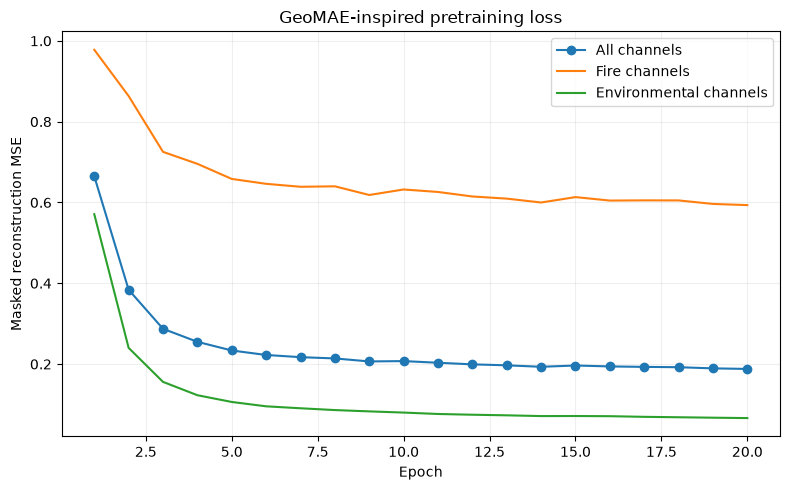

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_spatiotemporal\t2\figures\01_pretraining_loss.png


In [21]:
# 20. Training curve

history_df = pd.DataFrame(
    history
)

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.plot(
    history_df["epoch"],
    history_df["masked_mse"],
    marker="o",
    label="All channels",
)

ax.plot(
    history_df["epoch"],
    history_df["masked_fire_mse"],
    label="Fire channels",
)

ax.plot(
    history_df["epoch"],
    history_df["masked_env_mse"],
    label="Environmental channels",
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Masked reconstruction MSE")
ax.set_title("GeoMAE-inspired pretraining loss")
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

path = (
    FIGURE_DIR
    / "01_pretraining_loss.png"
)

plt.savefig(
    path,
    dpi=190,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path)

# PART D — August anomaly scoring

For every August center cell-day:

### Reconstruction anomaly
Force-mask only the current-day center token.

The model must reconstruct the center token from:
- the previous six days;
- surrounding cells;
- same-day surrounding cells.

Primary reconstruction anomaly:
- fire-channel MSE at the center token.

Secondary:
- environmental-channel MSE;
- total center-token MSE.

### Representation novelty
Run the model without masking and obtain the center-token latent representation.

Then calculate mean distance to the 10 nearest **May–July training representations**.

This gives a second, independent novelty score.

In [22]:
# 21. Score center reconstruction for arbitrary sample indices

@torch.no_grad()
def score_center_reconstruction(
    indices,
    batch_size=256,
):
    dataset = PatchDataset(
        X,
        VALID,
        indices,
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
    )

    rows = []

    model.eval()

    for x_batch, valid_batch, idx_batch in loader:
        x_batch = x_batch.to(
            DEVICE
        )

        valid_batch = valid_batch.to(
            DEVICE
        )

        forced_mask = torch.zeros_like(
            valid_batch
        )

        forced_mask[
            :,
            CENTER_TOKEN_INDEX,
        ] = True

        forced_mask = (
            forced_mask
            & valid_batch
        )

        prediction, _ = model(
            x_batch,
            valid_batch,
            forced_mask,
        )

        true_center = x_batch[
            :,
            CENTER_TOKEN_INDEX,
            :,
        ]

        pred_center = prediction[
            :,
            CENTER_TOKEN_INDEX,
            :,
        ]

        error = (
            pred_center
            - true_center
        ) ** 2

        total_err = (
            error.mean(
                dim=1
            )
            .detach()
            .cpu()
            .numpy()
        )

        fire_err = (
            error[
                :,
                FIRE_FEATURE_INDICES,
            ]
            .mean(
                dim=1
            )
            .detach()
            .cpu()
            .numpy()
        )

        env_err = (
            error[
                :,
                ENV_FEATURE_INDICES,
            ]
            .mean(
                dim=1
            )
            .detach()
            .cpu()
            .numpy()
        )

        for idx, te, fe, ee_ in zip(
            idx_batch.numpy(),
            total_err,
            fire_err,
            env_err,
        ):
            rows.append({
                "sample_index": int(idx),
                "mae_total_reconstruction_error": float(te),
                "mae_fire_reconstruction_error": float(fe),
                "mae_env_reconstruction_error": float(ee_),
            })

    return pd.DataFrame(
        rows
    )

In [23]:
# 22. August reconstruction scores

aug_recon = (
    score_center_reconstruction(
        aug_idx
    )
)

aug_scores = (
    META.iloc[
        aug_recon[
            "sample_index"
        ].to_numpy()
    ]
    .reset_index()
    .rename(
        columns={
            "index": "sample_index"
        }
    )
    .merge(
        aug_recon,
        on="sample_index",
        how="left",
        validate="one_to_one",
    )
)

print("August scored rows:", len(aug_scores))
display(aug_scores.head())

August scored rows: 4123


,sample_index,date,cell_id,grid_lat,grid_lon,fire_active,fire_count,frp_sum,mae_total_reconstruction_error,mae_fire_reconstruction_error,mae_env_reconstruction_error
0,10507,2026-08-01,regional025_10_22,-1.875,113.625,0,0.0,0.0,0.003603,0.001292,0.004296
1,10508,2026-08-01,regional025_10_23,-1.875,113.875,0,0.0,0.0,0.011162,0.037880,0.003147
2,10509,2026-08-01,regional025_10_24,-1.875,114.125,0,0.0,0.0,0.025762,0.025604,0.025809
3,10510,2026-08-01,regional025_10_25,-1.875,114.375,0,0.0,0.0,0.051956,0.160082,0.019519
4,10511,2026-08-01,regional025_10_26,-1.875,114.625,0,0.0,0.0,0.051636,0.114397,0.032807


In [24]:
# 23. Within-day reconstruction anomaly ranks

for col in [
    "mae_fire_reconstruction_error",
    "mae_env_reconstruction_error",
    "mae_total_reconstruction_error",
]:
    rank_col = (
        col
        + "__day_rank"
    )

    aug_scores[
        rank_col
    ] = (
        aug_scores
        .groupby(
            "date"
        )[col]
        .rank(
            pct=True,
            ascending=True,
            method="average",
        )
    )

print(
    "Higher rank = higher reconstruction anomaly."
)

Higher rank = higher reconstruction anomaly.


In [25]:
# 24. Encode center-token representations

@torch.no_grad()
def encode_center(
    indices,
    batch_size=256,
):
    dataset = PatchDataset(
        X,
        VALID,
        indices,
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
    )

    embeddings = []
    sample_indices = []

    model.eval()

    for x_batch, valid_batch, idx_batch in loader:
        x_batch = x_batch.to(
            DEVICE
        )

        valid_batch = valid_batch.to(
            DEVICE
        )

        latent = model.encode(
            x_batch,
            valid_batch,
            mask_positions=None,
        )

        center = (
            latent[
                :,
                CENTER_TOKEN_INDEX,
                :
            ]
            .detach()
            .cpu()
            .numpy()
        )

        embeddings.append(
            center
        )

        sample_indices.extend(
            idx_batch.numpy()
            .astype(int)
            .tolist()
        )

    return (
        np.concatenate(
            embeddings,
            axis=0,
        ),
        np.asarray(
            sample_indices
        ),
    )


train_embeddings, train_embedding_idx = (
    encode_center(
        train_idx
    )
)

aug_embeddings, aug_embedding_idx = (
    encode_center(
        aug_idx
    )
)

print(
    "Train embeddings:",
    train_embeddings.shape,
)

print(
    "August embeddings:",
    aug_embeddings.shape,
)

Train embeddings: (10507, 64)
August embeddings: (4123, 64)


In [26]:
# 25. Latent kNN novelty score

K_NEIGHBORS = 10

knn = NearestNeighbors(
    n_neighbors=K_NEIGHBORS,
    metric="euclidean",
    n_jobs=-1,
)

knn.fit(
    train_embeddings
)

distances, _ = knn.kneighbors(
    aug_embeddings
)

embedding_novelty = (
    distances.mean(
        axis=1
    )
)

embedding_score_df = pd.DataFrame({
    "sample_index": aug_embedding_idx,
    "embedding_knn_distance": embedding_novelty,
})

aug_scores = (
    aug_scores
    .merge(
        embedding_score_df,
        on="sample_index",
        how="left",
        validate="one_to_one",
    )
)

aug_scores[
    "embedding_knn_distance__day_rank"
] = (
    aug_scores
    .groupby(
        "date"
    )[
        "embedding_knn_distance"
    ]
    .rank(
        pct=True,
        ascending=True,
        method="average",
    )
)

display(
    aug_scores[
        [
            "date",
            "cell_id",
            "fire_active",
            "mae_fire_reconstruction_error",
            "mae_fire_reconstruction_error__day_rank",
            "embedding_knn_distance",
            "embedding_knn_distance__day_rank",
        ]
    ].head()
)

,date,cell_id,fire_active,mae_fire_reconstruction_error,mae_fire_reconstruction_error__day_rank,embedding_knn_distance,embedding_knn_distance__day_rank
0,2026-08-01,regional025_10_22,0,0.001292,0.097744,1.162857,0.150376
1,2026-08-01,regional025_10_23,0,0.037880,0.368421,0.993720,0.022556
2,2026-08-01,regional025_10_24,0,0.025604,0.323308,1.254516,0.248120
3,2026-08-01,regional025_10_25,0,0.160082,0.518797,1.307257,0.315789
4,2026-08-01,regional025_10_26,0,0.114397,0.473684,1.468967,0.428571


In [27]:
# 26. Agreement between the two GeoMAE-inspired anomaly views

rho, pvalue = spearmanr(
    aug_scores[
        "mae_fire_reconstruction_error__day_rank"
    ],
    aug_scores[
        "embedding_knn_distance__day_rank"
    ],
)

print(
    "Spearman rank correlation:",
    round(
        float(rho),
        4,
    ),
)

print(
    "p-value:",
    pvalue,
)

TOP_Q = 0.80

recon_high = (
    aug_scores[
        "mae_fire_reconstruction_error__day_rank"
    ]
    >= TOP_Q
)

latent_high = (
    aug_scores[
        "embedding_knn_distance__day_rank"
    ]
    >= TOP_Q
)

intersection = int(
    (
        recon_high
        & latent_high
    ).sum()
)

union = int(
    (
        recon_high
        | latent_high
    ).sum()
)

jaccard = (
    intersection / union
    if union
    else np.nan
)

print(
    "Top-20% Jaccard:",
    round(
        jaccard,
        4,
    ),
)

Spearman rank correlation: 0.4825
p-value: 1.757405828299119e-239
Top-20% Jaccard: 0.1957


# PART E — Compare against existing August research groups

NB24 does **not** use NB23C labels for training.

If NB23C exports exist, they are loaded only after the self-supervised model has been trained and scored.

This lets us ask:

> Does the learned representation independently assign higher anomaly to Emerging-3 or previous robust candidates?

This is an evaluation / interpretation step, not target leakage.

In [28]:
# 27. Optional merge with NB23C August positive-event analysis

NB23C_POSITIVE_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "environmental_context_refinement"
    / "t2"
    / "exports"
    / "august_positive_refined_anomaly.csv"
)

analysis_positive = pd.DataFrame()

if NB23C_POSITIVE_PATH.exists():
    nb23c_pos = pd.read_csv(
        NB23C_POSITIVE_PATH,
        parse_dates=[
            "date",
            "event_date",
        ],
    )

    positive_scores = (
        aug_scores[
            aug_scores[
                "fire_active"
            ].eq(1)
        ]
        .copy()
        .rename(
            columns={
                "date": "event_date"
            }
        )
    )

    analysis_positive = (
        nb23c_pos
        .merge(
            positive_scores[
                [
                    "event_date",
                    "cell_id",
                    "mae_fire_reconstruction_error",
                    "mae_fire_reconstruction_error__day_rank",
                    "mae_env_reconstruction_error",
                    "embedding_knn_distance",
                    "embedding_knn_distance__day_rank",
                ]
            ],
            on=[
                "event_date",
                "cell_id",
            ],
            how="inner",
        )
    )

    print(
        "Merged positive events:",
        len(
            analysis_positive
        ),
    )

    display(
        analysis_positive.head()
    )

else:
    print(
        "NB23C positive export not found. "
        "Group comparison will be skipped."
    )

Merged positive events: 2066


,date,cell_id,fire_count,frp_sum,fire_active,node_index,grid_lat,grid_lon,land_fraction,jrc_mean_water_occurrence,jrc_water_any_fraction,jrc_water50_fraction,jrc_water90_fraction,fire_count_lag1,fire_count_lag3,fire_count_lag7,frp_sum_lag1,frp_sum_lag3,frp_sum_lag7,fire_count_roll3,frp_sum_roll3,fire_count_roll7,frp_sum_roll7,target_fire_active_t1,active_days_prev3_incl_t,event_type_3d,active_days_prev7_incl_t,event_type_7d,temperature_mean,temperature_max,relative_humidity_mean,precipitation_sum,boundary_layer_height_mean,vapour_pressure_deficit_mean,wind_speed_mean,wind_speed_max,wind_u_mean,wind_v_mean,precip_roll3_sum,precip_roll7_sum,low_rain_day_lt1mm,low_rain_days_roll7,vpd_roll3_mean,vpd_roll7_mean,rh_roll3_mean,rh_roll7_mean,tempmax_roll3_mean,tempmax_roll7_mean,wind_roll3_mean,wind_roll7_mean,score__E0_ENV10_LR,score__E1_ANTECEDENT_LR,score__E2_ANTECEDENT_LAND_LR,score__E3_ANTECEDENT_LAND_HGB,env_rank__E0_ENV10_LR,env_rank__E1_ANTECEDENT_LR,env_rank__E2_ANTECEDENT_LAND_LR,env_rank__E3_ANTECEDENT_LAND_HGB,history_score,history_anomaly_day_rank,event_date,research_group,high_history,high_env_refined_lr,high_env_refined_hgb,robust_joint_high,mae_fire_reconstruction_error,mae_fire_reconstruction_error__day_rank,mae_env_reconstruction_error,embedding_knn_distance,embedding_knn_distance__day_rank
0,2026-08-04,regional025_10_22,0.0,0.00,0,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.00,0.0,0.00,1,0.0,Emerging,0.0,Emerging,28.270833,35.0,68.041667,0.0,765.208333,1.436250,6.583333,12.1,1.827639,6.169326,0.2,3.2,1,6.0,1.367500,1.138155,69.277778,73.898810,34.666667,34.014286,6.513889,5.586310,0.568222,0.417156,0.361069,0.580162,0.624060,0.714286,0.796992,0.473684,0.297914,0.763158,2026-08-05,Emerging-3,False,False,False,False,10.664015,0.872180,0.024910,2.551318,0.699248
1,2026-08-05,regional025_10_22,3.0,8.44,1,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.00,0.0,0.00,1,1.0,Persistent,1.0,Persistent,28.033333,34.6,67.875000,0.0,719.791667,1.436250,6.270833,10.1,1.034996,5.897645,0.0,0.8,1,7.0,1.447222,1.233571,67.875000,72.005952,34.966667,34.214286,6.484722,5.937500,0.678235,0.621725,0.563528,0.727841,0.563910,0.571429,0.631579,0.233083,0.791183,0.330827,2026-08-06,Persistent,False,False,False,False,7.633020,0.849624,0.022687,1.879275,0.293233
2,2026-08-16,regional025_10_22,0.0,0.00,0,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.00,0.0,0.00,1,0.0,Emerging,0.0,Emerging,28.058333,35.1,69.208333,0.1,583.750000,1.372083,5.841667,9.4,-1.895829,5.071252,1.2,1.2,1,6.0,1.249028,1.296250,71.805556,70.309524,34.866667,34.485714,5.900000,5.897619,0.687238,0.794548,0.743193,0.456217,0.593985,0.428571,0.488722,0.676692,0.297914,0.921053,2026-08-17,Emerging-3,True,False,False,False,16.572668,0.962406,0.125244,4.456660,0.661654
3,2026-08-17,regional025_10_22,5.0,19.81,1,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.00,0.0,0.00,1,1.0,Persistent,1.0,Persistent,28.516667,35.7,64.625000,0.0,808.333333,1.637500,7.291667,12.6,1.111555,6.751484,0.2,1.2,1,6.0,1.417083,1.337798,68.430556,69.708333,35.066667,34.642857,6.558333,6.058333,0.656373,0.617533,0.537810,0.518794,0.563910,0.684211,0.699248,0.578947,0.850374,0.571429,2026-08-18,Persistent,False,False,False,False,1.584055,0.300752,0.390904,6.661351,0.969925
4,2026-08-18,regional025_10_22,10.0,34.31,1,6,-1.875,113.625,1.0,0.231789,0.007125,0.002249,0.0,5.0,0.0,0.0,19.81,0.0,0.0,5.0,19.81,5.0,19.81,1,2.0,Persistent,2.0,Persistent,28.308333,36.4,59.291667,0.0,645.625000,1.822083,6.470833,10.3,-2.603719,5.445411,0.1,1.2,1,6.0,1.610556,1.408452,64.375000,68.309524,35.733333,34.914286,6.534722,6.032143,0.817681,0.816244,0.758864,0.396756,0.533835,0.556391,0.556391,0.781955,0.991501,0.406015,2026-08-19,Persistent,False,False,False,False,0.500252,0.180451,0.079167,5.139045,0.729323


In [29]:
# 28. Emerging vs Persistent summary

group_summary = pd.DataFrame()

if len(
    analysis_positive
):
    group_summary = (
        analysis_positive
        .groupby(
            "research_group"
        )
        .agg(
            events=(
                "cell_id",
                "size",
            ),
            recon_rank_mean=(
                "mae_fire_reconstruction_error__day_rank",
                "mean",
            ),
            recon_rank_median=(
                "mae_fire_reconstruction_error__day_rank",
                "median",
            ),
            latent_rank_mean=(
                "embedding_knn_distance__day_rank",
                "mean",
            ),
            latent_rank_median=(
                "embedding_knn_distance__day_rank",
                "median",
            ),
        )
        .reset_index()
    )

    display(
        group_summary
    )

,research_group,events,recon_rank_mean,recon_rank_median,latent_rank_mean,latent_rank_median
0,Emerging-3,217,0.77402,0.819549,0.554624,0.578947
1,Persistent,1849,0.58900,0.616541,0.695922,0.729323


In [30]:
# 29. Date-block bootstrap of Emerging - Persistent median difference

def date_block_bootstrap(
    df,
    value_col,
    n_boot=2000,
    seed=42,
):
    required_groups = {
        "Emerging-3",
        "Persistent",
    }

    if not required_groups.issubset(
        set(
            df[
                "research_group"
            ].dropna()
        )
    ):
        return None

    rng = np.random.default_rng(
        seed
    )

    dates = np.array(
        sorted(
            df[
                "event_date"
            ].unique()
        )
    )

    observed = (
        df.loc[
            df[
                "research_group"
            ].eq(
                "Emerging-3"
            ),
            value_col,
        ].median()
        -
        df.loc[
            df[
                "research_group"
            ].eq(
                "Persistent"
            ),
            value_col,
        ].median()
    )

    boot = []

    for _ in range(
        n_boot
    ):
        sampled_dates = rng.choice(
            dates,
            size=len(dates),
            replace=True,
        )

        b = pd.concat(
            [
                df[
                    df[
                        "event_date"
                    ].eq(d)
                ]
                for d
                in sampled_dates
            ],
            ignore_index=True,
        )

        em = b.loc[
            b[
                "research_group"
            ].eq(
                "Emerging-3"
            ),
            value_col,
        ]

        pe = b.loc[
            b[
                "research_group"
            ].eq(
                "Persistent"
            ),
            value_col,
        ]

        if len(em) and len(pe):
            boot.append(
                float(
                    em.median()
                    - pe.median()
                )
            )

    lo, hi = np.quantile(
        boot,
        [
            0.025,
            0.975,
        ],
    )

    return {
        "score": value_col,
        "observed_median_difference": float(
            observed
        ),
        "bootstrap_2.5%": float(
            lo
        ),
        "bootstrap_97.5%": float(
            hi
        ),
        "bootstrap_samples": len(
            boot
        ),
    }


bootstrap_results = []

if len(
    analysis_positive
):
    for col in [
        "mae_fire_reconstruction_error__day_rank",
        "embedding_knn_distance__day_rank",
    ]:
        result = (
            date_block_bootstrap(
                analysis_positive,
                col,
            )
        )

        if result is not None:
            bootstrap_results.append(
                result
            )

bootstrap_results = pd.DataFrame(
    bootstrap_results
)

if len(
    bootstrap_results
):
    display(
        bootstrap_results
    )

,score,observed_median_difference,bootstrap_2.5%,bootstrap_97.5%,bootstrap_samples
0,mae_fire_reconstruction_error__day_rank,0.203008,0.180451,0.225564,2000
1,embedding_knn_distance__day_rank,-0.150376,-0.248214,-0.090226,2000


In [31]:
# 30. Identify self-supervised high-anomaly August hotspot events

positive_aug = (
    aug_scores[
        aug_scores[
            "fire_active"
        ].eq(1)
    ]
    .copy()
)

positive_aug[
    "high_reconstruction_anomaly"
] = (
    positive_aug[
        "mae_fire_reconstruction_error__day_rank"
    ]
    >= TOP_Q
)

positive_aug[
    "high_latent_novelty"
] = (
    positive_aug[
        "embedding_knn_distance__day_rank"
    ]
    >= TOP_Q
)

positive_aug[
    "dual_high_geomae_candidate"
] = (
    positive_aug[
        "high_reconstruction_anomaly"
    ]
    &
    positive_aug[
        "high_latent_novelty"
    ]
)

dual_candidates = (
    positive_aug[
        positive_aug[
            "dual_high_geomae_candidate"
        ]
    ]
    .sort_values(
        [
            "mae_fire_reconstruction_error__day_rank",
            "embedding_knn_distance__day_rank",
        ],
        ascending=False,
    )
)

print(
    "August positive events:",
    len(
        positive_aug
    ),
)

print(
    "Dual-high GeoMAE-inspired candidates:",
    len(
        dual_candidates
    ),
)

display(
    dual_candidates[
        [
            "date",
            "cell_id",
            "grid_lat",
            "grid_lon",
            "fire_count",
            "frp_sum",
            "mae_fire_reconstruction_error__day_rank",
            "embedding_knn_distance__day_rank",
        ]
    ].head(40)
)

August positive events: 2106
Dual-high GeoMAE-inspired candidates: 226


,date,cell_id,grid_lat,grid_lon,fire_count,frp_sum,mae_fire_reconstruction_error__day_rank,embedding_knn_distance__day_rank
251,2026-08-02,regional025_8_32,-2.375,116.125,8.0,84.98,1.000000,0.984962
1212,2026-08-10,regional025_11_25,-1.625,114.375,14.0,71.38,1.000000,0.954887
836,2026-08-07,regional025_13_23,-1.125,113.875,7.0,20.71,1.000000,0.932331
28,2026-08-01,regional025_12_26,-1.375,114.625,2.0,21.74,1.000000,0.924812
1781,2026-08-14,regional025_2_26,-3.875,114.625,7.0,57.97,1.000000,0.917293
432,2026-08-04,regional025_12_31,-1.375,115.875,3.0,5.54,1.000000,0.894737
769,2026-08-06,regional025_7_30,-2.625,115.625,1.0,114.58,1.000000,0.887218
2057,2026-08-16,regional025_4_22,-3.375,113.625,12.0,156.30,1.000000,0.887218
955,2026-08-08,regional025_12_22,-1.375,113.625,10.0,92.27,1.000000,0.879699
586,2026-08-05,regional025_2_28,-3.875,115.125,6.0,37.23,1.000000,0.872180


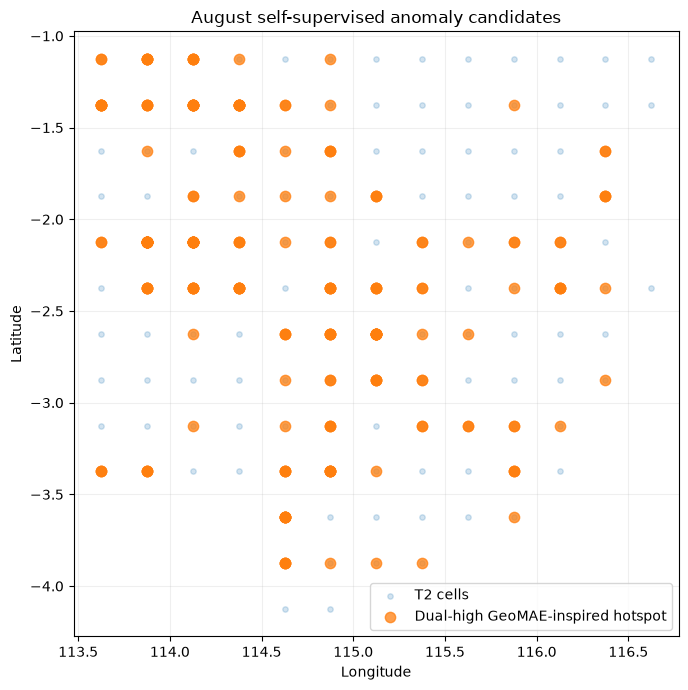

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_spatiotemporal\t2\figures\02_geomae_august_candidates.png


In [32]:
# 31. Spatial view of dual-high candidates

fig, ax = plt.subplots(
    figsize=(8, 7)
)

nodes = (
    META[
        META["date"]
        .between(
            DEV_START,
            DEV_END,
        )
    ][
        [
            "cell_id",
            "grid_lon",
            "grid_lat",
        ]
    ]
    .drop_duplicates()
)

ax.scatter(
    nodes["grid_lon"],
    nodes["grid_lat"],
    s=15,
    alpha=0.20,
    label="T2 cells",
)

if len(
    dual_candidates
):
    ax.scatter(
        dual_candidates[
            "grid_lon"
        ],
        dual_candidates[
            "grid_lat"
        ],
        s=55,
        alpha=0.75,
        label="Dual-high GeoMAE-inspired hotspot",
    )

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(
    "August self-supervised anomaly candidates"
)
ax.set_aspect(
    "equal",
    adjustable="box",
)
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

path = (
    FIGURE_DIR
    / "02_geomae_august_candidates.png"
)

plt.savefig(
    path,
    dpi=190,
    bbox_inches="tight",
)

plt.show()

print("Saved:", path)

# PART F — Decision gate

Do not declare GeoMAE successful merely because the Transformer trained.

A useful result should show at least some of the following:

1. masked reconstruction loss converges stably;
2. August center-token scores are not degenerate;
3. reconstruction anomaly and latent novelty have interpretable, non-identical behavior;
4. Emerging-3 tends to receive higher anomaly than Persistent under at least one learned score;
5. results are not concentrated in a tiny number of cells only;
6. learned anomaly adds information beyond the hand-crafted history/environmental ranks.

If these conditions fail, the architecture or pretext task should be revised rather than forcing the method into the thesis.

In [33]:
# 32. Cell concentration audit

cell_concentration = pd.DataFrame()

if len(
    dual_candidates
):
    cell_concentration = (
        dual_candidates
        .groupby(
            [
                "cell_id",
                "grid_lat",
                "grid_lon",
            ]
        )
        .size()
        .rename(
            "candidate_events"
        )
        .reset_index()
        .sort_values(
            "candidate_events",
            ascending=False,
        )
    )

    top5_share = (
        cell_concentration[
            "candidate_events"
        ]
        .head(5)
        .sum()
        / len(
            dual_candidates
        )
    )

    display(
        cell_concentration.head(20)
    )

    print(
        "Top-5-cell candidate share:",
        round(
            float(
                top5_share
            ),
            4,
        ),
    )
else:
    print(
        "No dual-high candidates."
    )

,cell_id,grid_lat,grid_lon,candidate_events
63,regional025_9_23,-2.125,113.875,17
64,regional025_9_24,-2.125,114.125,13
50,regional025_7_28,-2.625,115.125,10
13,regional025_12_24,-1.375,114.125,9
14,regional025_12_25,-1.375,114.375,8
11,regional025_12_22,-1.375,113.625,7
27,regional025_3_26,-3.625,114.625,7
32,regional025_4_27,-3.375,114.875,6
55,regional025_8_25,-2.375,114.375,6
19,regional025_13_23,-1.125,113.875,6


Top-5-cell candidate share: 0.2522


In [34]:
# 33. Save model and outputs

MODEL_PATH = (
    MODEL_DIR
    / "geomae_inspired_encoder.pt"
)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "token_features": TOKEN_FEATURES,
        "feature_mean": feature_mean.to_dict(),
        "feature_std": feature_std.to_dict(),
        "mask_ratio": MASK_RATIO,
        "temporal_days": TEMPORAL_DAYS,
        "spatial_offsets": SPATIAL_OFFSETS,
        "center_token_index": CENTER_TOKEN_INDEX,
        "pretrain_end": str(
            PRETRAIN_END.date()
        ),
    },
    MODEL_PATH,
)

history_df.to_csv(
    EXPORT_DIR
    / "pretraining_history.csv",
    index=False,
)

aug_scores.to_csv(
    EXPORT_DIR
    / "august_geomae_scores_all_cells.csv",
    index=False,
)

positive_aug.to_csv(
    EXPORT_DIR
    / "august_geomae_scores_positive_events.csv",
    index=False,
)

dual_candidates.to_csv(
    EXPORT_DIR
    / "august_geomae_dual_high_candidates.csv",
    index=False,
)

if len(
    group_summary
):
    group_summary.to_csv(
        EXPORT_DIR
        / "geomae_group_summary.csv",
        index=False,
    )

if len(
    bootstrap_results
):
    bootstrap_results.to_csv(
        EXPORT_DIR
        / "geomae_group_bootstrap.csv",
        index=False,
    )

if len(
    cell_concentration
):
    cell_concentration.to_csv(
        EXPORT_DIR
        / "geomae_candidate_cell_concentration.csv",
        index=False,
    )

normalization_table.to_csv(
    EXPORT_DIR
    / "train_normalization_statistics.csv",
    index=False,
)

metadata = {
    "notebook": "24_geomae_inspired_spatiotemporal_masked_pretraining",
    "method": "GeoMAE-inspired spatiotemporal masked Transformer",
    "literal_geomae_reproduction": False,
    "pretraining_supervision": "self-supervised masked reconstruction",
    "pretraining_end": str(
        PRETRAIN_END.date()
    ),
    "development_period": "August 2026",
    "september_used": False,
    "temporal_days": TEMPORAL_DAYS,
    "spatial_patch": "3x3",
    "tokens_per_sample": N_TOKENS,
    "mask_ratio": MASK_RATIO,
    "token_features": TOKEN_FEATURES,
    "primary_anomaly_score": "mae_fire_reconstruction_error__day_rank",
    "secondary_anomaly_score": "embedding_knn_distance__day_rank",
    "important_limit": (
        "Anomaly scores do not identify anthropogenic, intentional, "
        "illegal, plantation-related, cigarette-related, or natural ignition."
    ),
}

(
    EXPORT_DIR
    / "nb24_methodology_metadata.json"
).write_text(
    json.dumps(
        metadata,
        indent=2,
    ),
    encoding="utf-8",
)

print("Saved model:", MODEL_PATH)
print("Saved outputs:", EXPORT_DIR)

Saved model: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_spatiotemporal\t2\models\geomae_inspired_encoder.pt
Saved outputs: c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_spatiotemporal\t2\exports


In [35]:
# 34. Automatic review summary

print("=== NB24 AUTOMATIC REVIEW ===")
print()

print(
    "Best masked training MSE:",
    round(
        best_loss,
        6,
    ),
)

print(
    "August scored cell-days:",
    len(
        aug_scores
    ),
)

print(
    "August actual hotspot cell-days:",
    len(
        positive_aug
    ),
)

print(
    "Dual-high candidates:",
    len(
        dual_candidates
    ),
)

print(
    "Reconstruction-vs-latent Spearman:",
    round(
        float(
            rho
        ),
        4,
    ),
)

print(
    "Top-20% Jaccard:",
    round(
        float(
            jaccard
        ),
        4,
    ),
)

if len(
    group_summary
):
    print()
    print(
        "Emerging vs Persistent:"
    )

    display(
        group_summary
    )

if len(
    bootstrap_results
):
    print()
    print(
        "Date-block bootstrap:"
    )

    display(
        bootstrap_results
    )

print()
print(
    "Interpretation boundary:"
)
print(
    "GeoMAE-inspired anomaly != human ignition."
)

=== NB24 AUTOMATIC REVIEW ===

Best masked training MSE: 0.18796
August scored cell-days: 4123
August actual hotspot cell-days: 2106
Dual-high candidates: 226
Reconstruction-vs-latent Spearman: 0.4825
Top-20% Jaccard: 0.1957

Emerging vs Persistent:


,research_group,events,recon_rank_mean,recon_rank_median,latent_rank_mean,latent_rank_median
0,Emerging-3,217,0.77402,0.819549,0.554624,0.578947
1,Persistent,1849,0.58900,0.616541,0.695922,0.729323



Date-block bootstrap:


,score,observed_median_difference,bootstrap_2.5%,bootstrap_97.5%,bootstrap_samples
0,mae_fire_reconstruction_error__day_rank,0.203008,0.180451,0.225564,2000
1,embedding_knn_distance__day_rank,-0.150376,-0.248214,-0.090226,2000



Interpretation boundary:
GeoMAE-inspired anomaly != human ignition.


# What to send back

After **Run All**, send the executed NB24 notebook.

The most important outputs are:

1. training-loss curve;
2. final masked reconstruction losses;
3. reconstruction-vs-latent rank correlation;
4. Emerging vs Persistent group summary;
5. date-block bootstrap;
6. number and locations of dual-high candidates;
7. top-5-cell concentration.

Then we decide whether this method is genuinely adding value or whether the pretext task must be redesigned.

Do **not** tune on September.